# The Solow model

**Lecture 11 · Wednesday, 25 November 2026 · Notebook 1 of 1**

We take a small economic model all the way from equations to results on the screen. **The focus is programming, not growth theory:** the basic Solow model fits on one page, and it lets us use everything from the previous lectures:

- a **class** for the model (Lecture 3),
- a **loop** to simulate it, and **plots** of the results (Lectures 3 and 5),
- a **root-finder** for the steady state (Lecture 7) and an **optimizer** for the best savings rate (Lecture 6),
- **known answers** as tests of our code.

You meet the same model in Macroeconomics I. Nothing here requires more than the next two cells.

## How to work

| Recording | Sections |
| --- | --- |
| Video 11A: The model as a class, and tests | 1–3 |
| Video 11B: Steady state and convergence | 4–6 |
| Video 11C: Experiments with the savings rate | 7–8 |

The questions for class are in **`Exercises.ipynb`**. **Before class (Tuesday 1 December, 23:59):** solve warm-ups **W1–W2** there, enter your answers in the Absalon quiz and upload the notebook. Class is on Wednesday 2 December, together with Lecture 12.

**Table of contents**<a id='toc0_'></a>
- 1. [The model](#toc1_)
- 2. [The model as a class](#toc2_)
- 3. [Testing the code](#toc3_)
- 4. [The steady state with a root-finder](#toc4_)
- 5. [The steady-state diagram](#toc5_)
- 6. [Convergence](#toc6_)
- 7. [A permanent rise in the savings rate](#toc7_)
- 8. [Which savings rate is best?](#toc8_)
- 9. [Summary](#toc9_)

<a id='video-11a'></a>
> **Start Video 11A**  
> Question: how do we turn three equations into code we can trust?

## 1. <a id='toc1_'></a>[The model](#toc0_)

Everything is **per worker**: $k_t$ is capital (machines, buildings, roads), $y_t$ output, $i_t$ investment and $c_t$ consumption.

**Production:** $y_t = k_t^{\alpha}$, with $0<\alpha<1$. More capital gives more output, but each extra machine adds less than the one before.

**Saving:** a constant share $s$ of output is invested, the rest is consumed: $i_t = s\,y_t$ and $c_t = (1-s)\,y_t$.

**Accumulation:** next period's capital is today's investment plus what is left after a share $\delta$ has worn out:

$$k_{t+1} = s\,k_t^{\alpha} + (1-\delta)\,k_t.$$

This one equation **is** the model: from a starting point $k_0$, it determines the whole future.

**Steady state.** Capital stops changing when investment exactly replaces what wears out, $s\,(k^*)^{\alpha} = \delta k^*$. Solving by hand:

$$k^* = \left(\frac{s}{\delta}\right)^{\frac{1}{1-\alpha}},\qquad y^* = (k^*)^{\alpha},\qquad c^* = (1-s)\,y^*.$$

A formula we can compute by hand is **very useful**: it lets us test our code. A period here is several years, which is why $\delta = 0.30$.

## 2. <a id='toc2_'></a>[The model as a class](#toc0_)

The model lives in its own file, **`solow.py`**: the notebook *uses* the model, the `.py` file *defines* it. This is how you should organize your model project too. The class, in short:

```python
class SolowModel:

    def __init__(self, alpha=1/3, s=0.20, delta=0.30, k0=0.10, T=50):
        self.alpha = alpha        # parameters become attributes
        ...

    def f(self, k):               # one method per equation
        return k**self.alpha

    def k_next(self, k):
        return self.s*self.f(k) + (1 - self.delta)*k

    def steady_state(self):       # the formula above
        ...

    def simulate(self, s_path=None):   # a loop over time
        ...
```

Open `solow.py` and read along. Default values in `__init__` mean we only type the parameters we want to change.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

from solow import SolowModel

In [2]:
model = SolowModel()                 # all default parameters
model_high_s = SolowModel(s=0.30)    # only the savings rate is changed

print(f'baseline:      s = {model.s:.2f}, delta = {model.delta:.2f}')
print(f'higher saving: s = {model_high_s.s:.2f}, delta = {model_high_s.delta:.2f}')

baseline:      s = 0.20, delta = 0.30
higher saving: s = 0.30, delta = 0.30


The steady state from the formula:

**Pause and predict:** does the economy with higher saving have more or less capital in steady state?

In [3]:
k_ss, y_ss, c_ss = model.steady_state()
print(f'baseline:      k* = {k_ss:.4f}, y* = {y_ss:.4f}, c* = {c_ss:.4f}')

k_hi, y_hi, c_hi = model_high_s.steady_state()
print(f'higher saving: k* = {k_hi:.4f}, y* = {y_hi:.4f}, c* = {c_hi:.4f}')

baseline:      k* = 0.5443, y* = 0.8165, c* = 0.6532
higher saving: k* = 1.0000, y* = 1.0000, c* = 0.7000


The simulation stores its results in arrays, one value per period: `model.k_path`, `model.y_path`, `model.i_path` and `model.c_path`.

In [4]:
model.simulate()
print('first five periods of k:', model.k_path[:5].round(4))
print('last period of k:       ', model.k_path[-1].round(4))

first five periods of k: [0.1    0.1628 0.2232 0.2776 0.3247]
last period of k:        0.5443


## 3. <a id='toc3_'></a>[Testing the code](#toc0_)

Before we *use* a model, we check that it does what we think. `assert condition, message` does nothing when the condition is `True`, and stops with the message when it is `False`. The trick is to find cases where we **already know the answer**:

1. an economy that **starts** in the steady state must **stay** there;
2. with **no saving**, capital only wears out: $k_t = (1-\delta)^t k_0$;
3. everything produced is consumed or invested: $y_t = c_t + i_t$.

In [5]:
# test 1: the steady state is a resting point
test = SolowModel(k0=k_ss, T=20)
test.simulate()
assert np.allclose(test.k_path, k_ss), 'the economy leaves the steady state'

# test 2: with s = 0 capital only wears out
test = SolowModel(s=0.0, k0=1.0, T=20)
test.simulate()
assert np.allclose(test.k_path, (1 - test.delta)**np.arange(20)), 'wrong decay without saving'   # (1-delta)**t for t = 0, ..., 19

# test 3: output is consumption plus investment
model.simulate()
assert np.allclose(model.y_path, model.c_path + model.i_path), 'the accounting does not add up'

print('all tests passed')

all tests passed


**No news is good news.** Rerun the tests every time you change the class: a failing test points straight at the bug, a wrong figure does not.

> **Stop Video 11A.** You can create a model, compute its steady state, simulate it and test it.

<a id='video-11b'></a>
> **Start Video 11B**  
> Question: does the economy really move to the steady state, and from any starting point?

## 4. <a id='toc4_'></a>[The steady state with a root-finder](#toc0_)

Most models have **no formula** for the steady state. Then we solve $k_{t+1} - k_t = 0$ numerically, with `brentq` from Lecture 7. The method `solve_steady_state` does exactly that:

```python
def steady_state_gap(self, k):
    return self.k_next(k) - k

def solve_steady_state(self):
    result = optimize.root_scalar(self.steady_state_gap, bracket=[1e-6, 100.0], method='brentq')
    if not result.converged:
        raise RuntimeError(result.flag)
    return result.root
```

Here the formula gives us a free test of the root-finder:

In [6]:
k_numerical = model.solve_steady_state()
print(f'k* from the formula:     {k_ss:.8f}')
print(f'k* from the root-finder: {k_numerical:.8f}')
assert np.isclose(k_ss, k_numerical), 'formula and root-finder disagree'

k* from the formula:     0.54433105
k* from the root-finder: 0.54433105


When you extend a model and the formula is gone, the root-finder still works, and you already know you can trust it.

## 5. <a id='toc5_'></a>[The steady-state diagram](#toc0_)

The classic figure: output $f(k)$, investment $s f(k)$ and depreciation $\delta k$. Where investment crosses depreciation, capital stops changing.

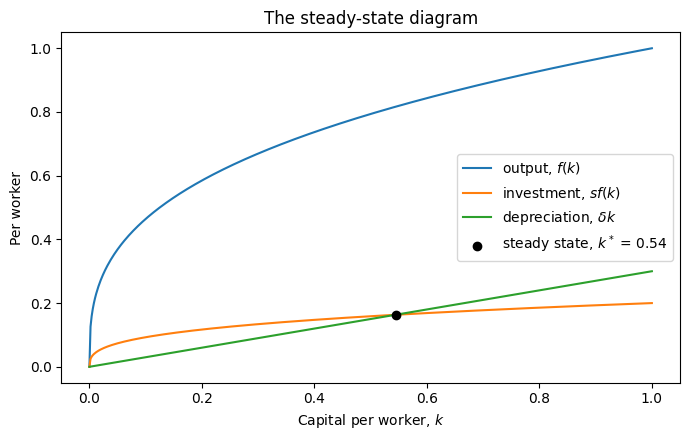

In [7]:
k_grid = np.linspace(0.0, 1.0, 500)

fig = plt.figure(figsize=(7, 4.5))
ax = fig.add_subplot(1, 1, 1)
ax.plot(k_grid, model.f(k_grid), label='output, $f(k)$')
ax.plot(k_grid, model.s*model.f(k_grid), label='investment, $s f(k)$')
ax.plot(k_grid, model.delta*k_grid, label=r'depreciation, $\delta k$')
ax.scatter(k_ss, model.delta*k_ss, color='black', zorder=3, label=f'steady state, $k^*$ = {k_ss:.2f}')
ax.set_xlabel('Capital per worker, $k$')
ax.set_ylabel('Per worker')
ax.set_title('The steady-state diagram')
ax.legend()
fig.tight_layout()
plt.show()

**Reading the figure:** left of $k^*$, investment is above depreciation, so capital grows. Right of $k^*$, it shrinks. The economy is pulled towards $k^*$ from both sides.

## 6. <a id='toc6_'></a>[Convergence](#toc0_)

We check the figure's promise by simulation: one economy starts far below the steady state, one far above.

**Pause and predict:** where are both economies after 40 periods?

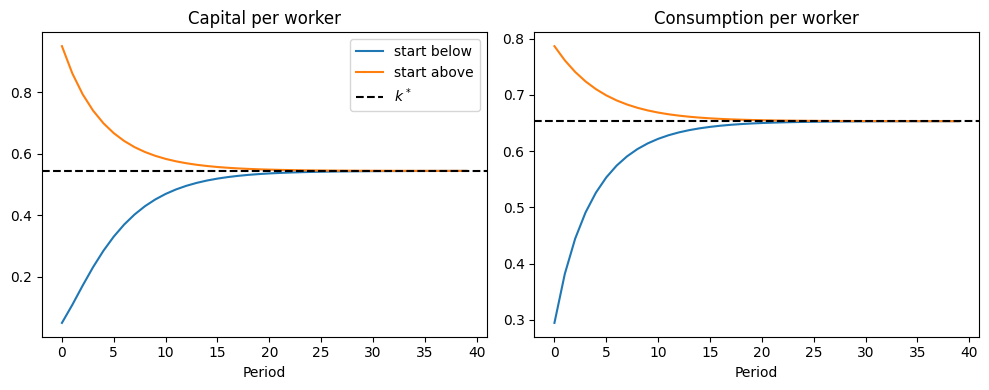

after 40 periods: 0.5442 and 0.5444; k* = 0.5443


In [8]:
below = SolowModel(k0=0.05, T=40)
above = SolowModel(k0=0.95, T=40)
below.simulate()
above.simulate()

fig = plt.figure(figsize=(10, 4))
ax = fig.add_subplot(1, 2, 1)
ax.plot(below.k_path, label='start below')
ax.plot(above.k_path, label='start above')
ax.axhline(k_ss, color='black', linestyle='--', label='$k^*$')
ax.set_xlabel('Period')
ax.set_title('Capital per worker')
ax.legend()

ax = fig.add_subplot(1, 2, 2)
ax.plot(below.c_path, label='start below')
ax.plot(above.c_path, label='start above')
ax.axhline(c_ss, color='black', linestyle='--', label='$c^*$')
ax.set_xlabel('Period')
ax.set_title('Consumption per worker')
fig.tight_layout()
plt.show()

print(f'after 40 periods: {below.k_path[-1]:.4f} and {above.k_path[-1]:.4f}; k* = {k_ss:.4f}')

Both economies end at $k^*$. The steps are large far from the steady state and small close to it: convergence is fast at first and then slow.

> **Stop Video 11B.** You can find a steady state numerically, draw the model's classic figure and show convergence by simulation.

<a id='video-11c'></a>
> **Start Video 11C**  
> Question: should a country save more?

## 7. <a id='toc7_'></a>[A permanent rise in the savings rate](#toc0_)

The economy starts in its steady state with $s=0.20$. In period 10 the savings rate rises permanently to $0.30$. We build the path of $s$ as an array and pass it to `simulate`.

**Pause and predict:** what happens to consumption in period 10, and in the long run?

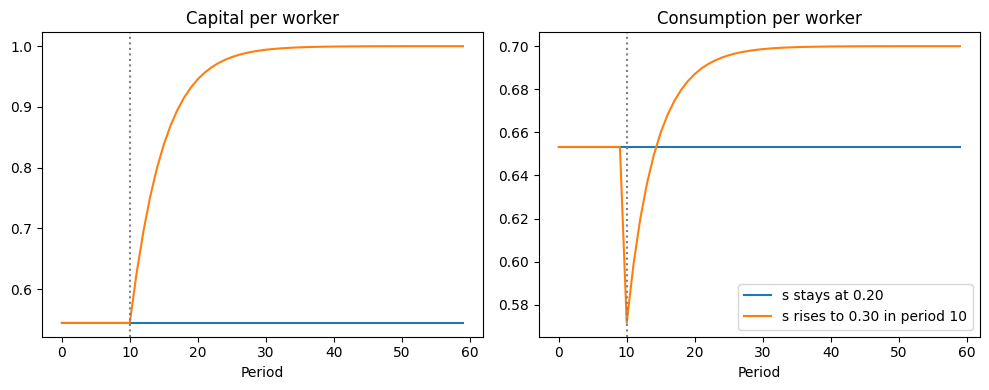

consumption in period 9: 0.6532, period 10: 0.5715, period 59: 0.7000


In [9]:
T = 60
s_path = np.full(T, 0.20)        # an array with T copies of 0.20
s_path[10:] = 0.30

base = SolowModel(k0=k_ss, T=T)
base.simulate()

rise = SolowModel(k0=k_ss, T=T)
rise.simulate(s_path=s_path)

fig = plt.figure(figsize=(10, 4))
for j, (name, path_base, path_rise) in enumerate([('Capital per worker', base.k_path, rise.k_path),
                                                  ('Consumption per worker', base.c_path, rise.c_path)]):
    ax = fig.add_subplot(1, 2, j + 1)
    ax.plot(path_base, label='s stays at 0.20')
    ax.plot(path_rise, label='s rises to 0.30 in period 10')
    ax.axvline(10, color='grey', linestyle=':')
    ax.set_xlabel('Period')
    ax.set_title(name)
ax.legend()
fig.tight_layout()
plt.show()

print(f'consumption in period 9: {rise.c_path[9]:.4f}, period 10: {rise.c_path[10]:.4f}, period {T-1}: {rise.c_path[-1]:.4f}')

Consumption **falls** at first: more of today's output is invested. Then capital builds up, output grows, and consumption ends **higher** than before. Saving more means giving up consumption today for more later.

## 8. <a id='toc8_'></a>[Which savings rate is best?](#toc0_)

If we care about consumption in the long run, which savings rate gives the **highest steady-state consumption** $c^*$? Saving too little leaves little capital; saving too much leaves little to consume. We answer it twice: with a grid (Lecture 6) and with `minimize_scalar`.

In [10]:
def c_star(s, alpha=1/3, delta=0.30):
    """Steady-state consumption for the savings rate s."""
    return SolowModel(alpha=alpha, s=s, delta=delta).steady_state()[2]


# a. grid
s_grid = np.linspace(0.01, 0.99, 99)
c_grid = np.array([c_star(s) for s in s_grid])
s_best_grid = s_grid[np.argmax(c_grid)]

# b. optimizer: minimize minus consumption; lambda (Lecture 3) is a one-line function of s
result = optimize.minimize_scalar(lambda s: -c_star(s), bounds=(0.01, 0.99), method='bounded')

print(f'best savings rate on the grid:      {s_best_grid:.4f}')
print(f'best savings rate with an optimizer: {result.x:.4f}')

best savings rate on the grid:      0.3300
best savings rate with an optimizer: 0.3333


**A known answer as a test.** For this model, pen and paper give the best savings rate $s = \alpha$ (the *golden rule*). Our optimizer finds $\alpha = 1/3$. Change $\alpha$ and check that the answer follows:

In [11]:
for alpha in [0.25, 0.40]:
    result = optimize.minimize_scalar(lambda s: -c_star(s, alpha=alpha), bounds=(0.01, 0.99), method='bounded')
    print(f'alpha = {alpha:.2f}: best savings rate = {result.x:.4f}')

alpha = 0.25: best savings rate = 0.2500
alpha = 0.40: best savings rate = 0.4000


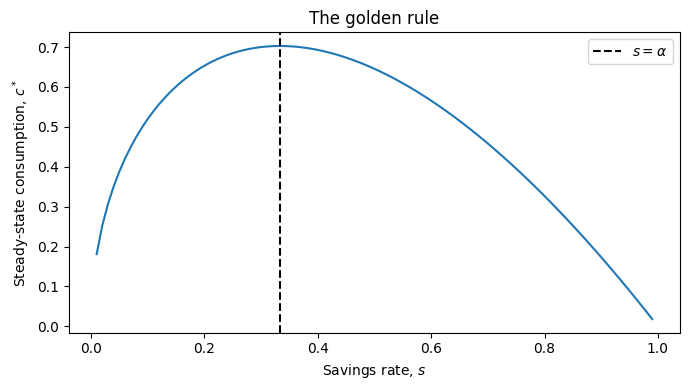

In [12]:
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(1, 1, 1)
ax.plot(s_grid, c_grid)
ax.axvline(1/3, color='black', linestyle='--', label=r'$s = \alpha$')
ax.set_xlabel('Savings rate, $s$')
ax.set_ylabel('Steady-state consumption, $c^*$')
ax.set_title('The golden rule')
ax.legend()
fig.tight_layout()
plt.show()

## 9. <a id='toc9_'></a>[Summary](#toc0_)

| Step | Tool | Lecture |
| --- | --- | --- |
| write the model | a class in a `.py` file | 3 |
| check it | `assert` with known answers | 6–8 |
| steady state | formula, and `brentq` | 7 |
| dynamics | a loop over time, plots | 3, 5 |
| best savings rate | grid and `minimize_scalar` | 6 |

**The recipe for any model:** write it as a class, test it where you know the answer, then use it.

> **Stop Video 11C.** End of Lecture 11's recording sequence. In Lecture 12 we use the same recipe for a market.